In [1]:
# %load_ext autoreload
# %autoreload 2

In [1]:
from utils_synthesis import *

In [2]:
df, df_metrics, df_model = read_and_process_csv(PATH)

papers -- total: 72
papers -- new generative method : 65


# MODEL

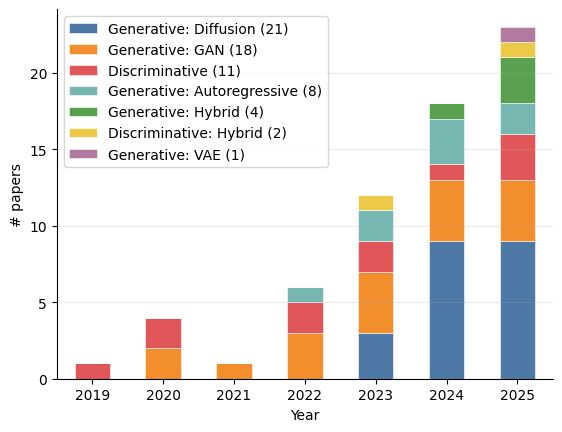

In [3]:
plot_model_per_year(df_model)

# PRE / POST PROCESSING

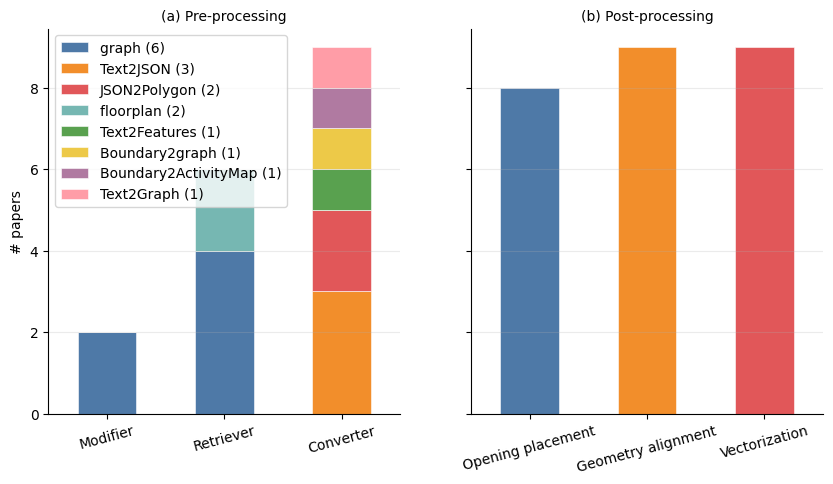

In [4]:
plot_pre_post_processing(df_model)

# INPUT / OUTPUT

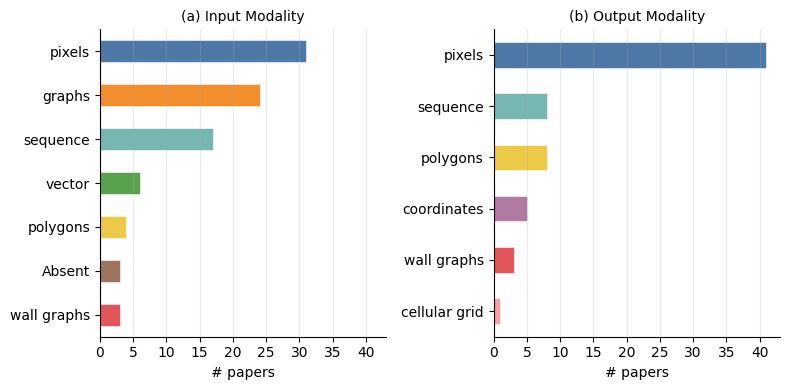

In [5]:
plot_input_output_modality(df_model)

In [6]:
# plot_input_output_content(df_model)

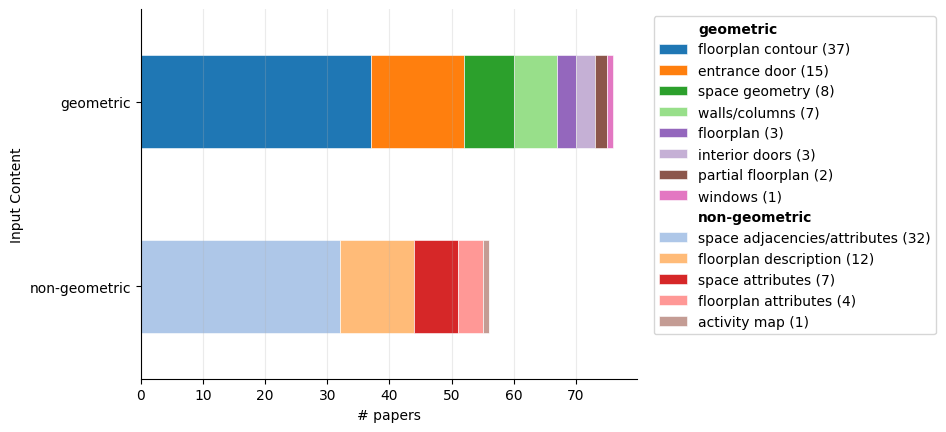

In [5]:
plot_input_content(df_model)

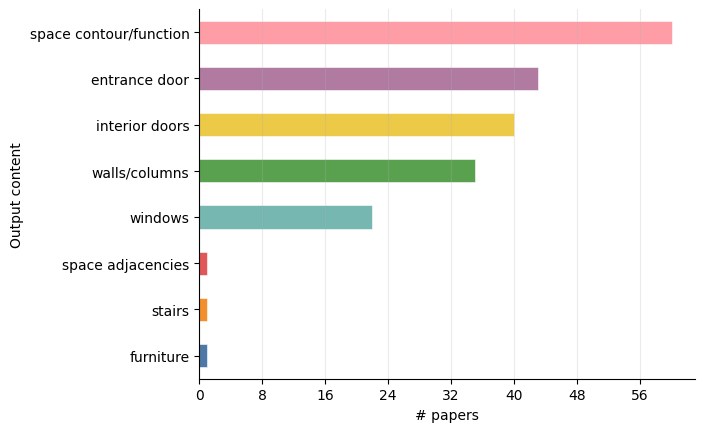

In [8]:
plot_output_content(df_model)

# INPUT: MODALITY / CONTENT

In [4]:
plot_sankey_input_modality_content(df_model)

(<Figure size 1800x1200 with 1 Axes>,
 <Axes: title={'center': 'Modality → Content → Content Group'}>)

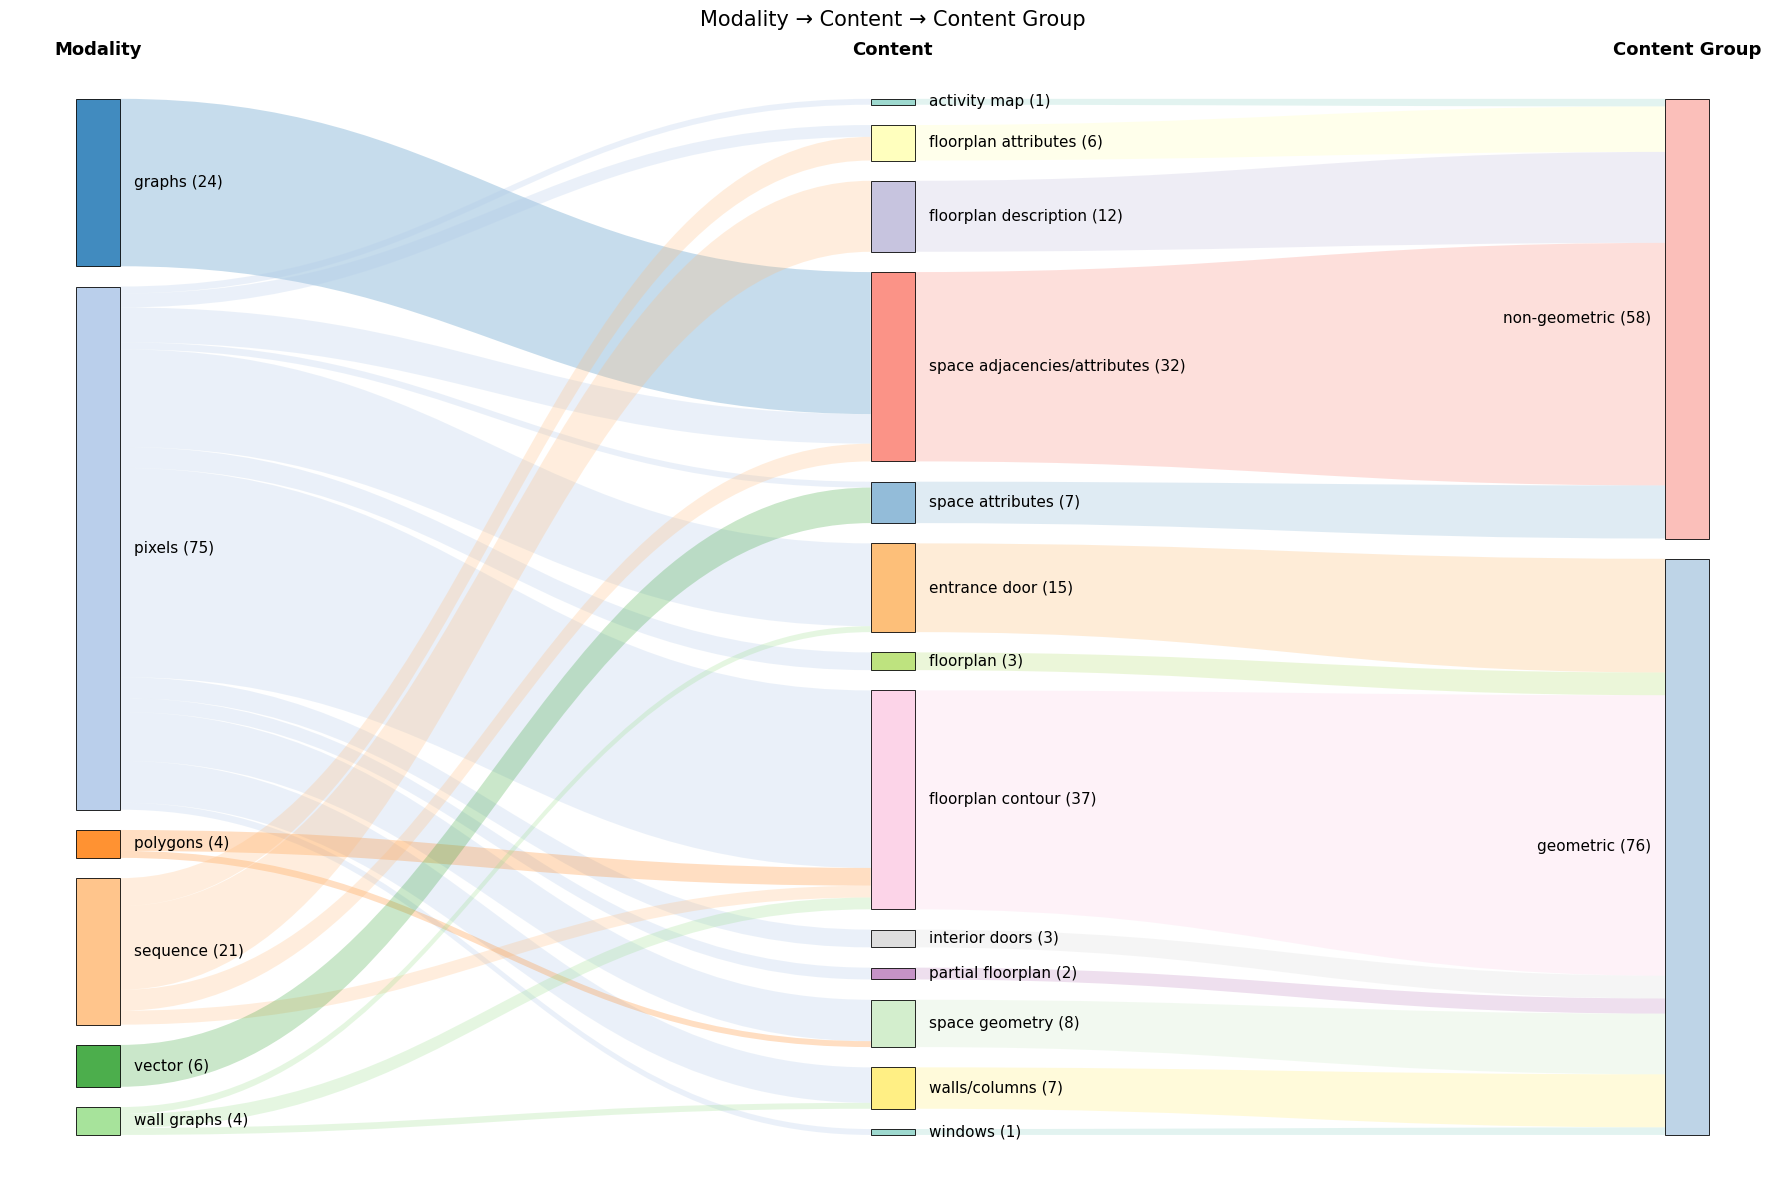

In [88]:
df3_levels = pd.read_csv("data/results/input_modality_content.csv")
df3_levels = df3_levels[["level1", "level2", "count"]].copy()

level2_to_level3 = {
    "space adjacencies/attributes": "non-geometric",
    "floorplan description": "non-geometric",
    "space attributes": "non-geometric",
    "floorplan attributes": "non-geometric",
    "activity map": "non-geometric",


    "floorplan contour": "geometric",
    "entrance door": "geometric",
    "space geometry": "geometric",
    "walls/columns": "geometric",
    "floorplan": "geometric",
    "interior doors": "geometric",
    "partial floorplan": "geometric",
    "windows": "geometric",
}

plot_sankey_3levels_from_mapping(
    df3_levels,
    level2_to_level3,
    level1_col="level1",
    level2_col="level2",
    value_col="count",
    title="Modality → Content → Content Group",
    save_path=None,
)

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle


def plot_sankey_3levels_from_mapping(
    df,
    level2_to_level3,
    level1_col="level1",
    level2_col="level2",
    value_col="count",
    level1_order=None,
    level2_order=None,
    level3_order=None,
    title="Level 1 → Level 2 → Level 3",
    figsize=(18, 12),
    node_width=0.025,
    node_gap=0.018,
    column_x=(0.05, 0.50, 0.95),
    link_alpha=0.25,
    node_alpha=0.85,
    font_size=11,
    save_path=None,
    dpi=300,
):
    """
    Draw a three-level Sankey diagram with non-overlapping nodes.

    Parameters
    ----------
    df : pandas.DataFrame
        Must contain level1, level2, and count columns.

    level2_to_level3 : dict
        Mapping from every Level-2 category to a Level-3 category.

    level1_order, level2_order, level3_order : list, optional
        Explicit top-to-bottom node order for each level.

    save_path : str, optional
        Example: "sankey.svg", "sankey.pdf", or "sankey.png".
    """

    # ============================================================
    # 1. Validate and prepare data
    # ============================================================
    required = {level1_col, level2_col, value_col}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    data = df[[level1_col, level2_col, value_col]].copy()

    data = data.dropna(
        subset=[level1_col, level2_col, value_col]
    )

    data[level1_col] = (
        data[level1_col]
        .astype(str)
        .str.strip()
    )

    data[level2_col] = (
        data[level2_col]
        .astype(str)
        .str.strip()
    )

    data[value_col] = pd.to_numeric(
        data[value_col],
        errors="raise",
    )

    if (data[value_col] < 0).any():
        raise ValueError("Counts cannot be negative.")

    mapping = {
        str(level2).strip(): str(level3).strip()
        for level2, level3 in level2_to_level3.items()
    }

    data["level3"] = data[level2_col].map(mapping)

    unmapped = sorted(
        data.loc[data["level3"].isna(), level2_col]
        .unique()
    )

    if unmapped:
        raise ValueError(
            "Missing Level-2 categories in mapping:\n"
            + "\n".join(f"- {item}" for item in unmapped)
        )

    # ============================================================
    # 2. Aggregate links
    # ============================================================
    links_12 = (
        data.groupby(
            [level1_col, level2_col],
            as_index=False,
        )[value_col]
        .sum()
        .rename(
            columns={
                level1_col: "source",
                level2_col: "target",
                value_col: "value",
            }
        )
    )

    links_23 = (
        data.groupby(
            [level2_col, "level3"],
            as_index=False,
        )[value_col]
        .sum()
        .rename(
            columns={
                level2_col: "source",
                "level3": "target",
                value_col: "value",
            }
        )
    )

    # ============================================================
    # 3. Determine node order
    # ============================================================
    def resolve_order(existing, specified=None):
        existing = list(pd.Index(existing).unique())

        if specified is None:
            return existing

        specified = [str(item).strip() for item in specified]

        ordered = [
            item for item in specified
            if item in existing
        ]

        ordered.extend(
            item for item in existing
            if item not in ordered
        )

        return ordered

    level1_nodes = resolve_order(
        links_12["source"],
        level1_order,
    )

    level3_nodes = resolve_order(
        links_23["target"],
        level3_order,
    )

    level3_position = {
        node: i
        for i, node in enumerate(level3_nodes)
    }

    level2_group = (
        links_23
        .set_index("source")["target"]
        .to_dict()
    )

    raw_level2_nodes = list(
        pd.Index(links_12["target"]).unique()
    )

    if level2_order is None:
        # Group Level-2 nodes by Level-3 destination.
        level2_nodes = sorted(
            raw_level2_nodes,
            key=lambda node: (
                level3_position[level2_group[node]],
                node,
            ),
        )
    else:
        level2_nodes = resolve_order(
            raw_level2_nodes,
            level2_order,
        )

    # ============================================================
    # 4. Calculate node totals
    # ============================================================
    level1_counts = (
        links_12.groupby("source")["value"]
        .sum()
        .to_dict()
    )

    level2_counts = (
        links_12.groupby("target")["value"]
        .sum()
        .to_dict()
    )

    level3_counts = (
        links_23.groupby("target")["value"]
        .sum()
        .to_dict()
    )

    # ============================================================
    # 5. Compute non-overlapping vertical node positions
    # ============================================================
    def calculate_node_boxes(
        nodes,
        counts,
        gap,
        bottom=0.04,
        top=0.96,
    ):
        """
        Return {node: (y_bottom, y_top)}.

        Heights are proportional to counts. Gaps are explicitly
        reserved, so nodes cannot overlap.
        """

        if not nodes:
            return {}

        available_height = top - bottom
        total_gap = gap * max(len(nodes) - 1, 0)
        flow_height = available_height - total_gap

        if flow_height <= 0:
            raise ValueError(
                "node_gap is too large for the number of nodes."
            )

        weights = np.array(
            [float(counts[node]) for node in nodes],
            dtype=float,
        )

        total_weight = weights.sum()

        if total_weight <= 0:
            weights = np.ones(len(nodes))
            total_weight = len(nodes)

        heights = flow_height * weights / total_weight

        boxes = {}
        cursor = top

        # Draw in the supplied top-to-bottom order.
        for node, height in zip(nodes, heights):
            y_top = cursor
            y_bottom = y_top - height

            boxes[node] = (y_bottom, y_top)

            cursor = y_bottom - gap

        return boxes

    boxes_1 = calculate_node_boxes(
        level1_nodes,
        level1_counts,
        node_gap,
    )

    boxes_2 = calculate_node_boxes(
        level2_nodes,
        level2_counts,
        node_gap,
    )

    boxes_3 = calculate_node_boxes(
        level3_nodes,
        level3_counts,
        node_gap,
    )

    # ============================================================
    # 6. Colours
    # ============================================================
    cmap_1 = plt.colormaps["tab20"]
    cmap_2 = plt.colormaps["Set3"]
    cmap_3 = plt.colormaps["Pastel1"]

    colors_1 = {
        node: cmap_1(i % cmap_1.N)
        for i, node in enumerate(level1_nodes)
    }

    colors_2 = {
        node: cmap_2(i % cmap_2.N)
        for i, node in enumerate(level2_nodes)
    }

    colors_3 = {
        node: cmap_3(i % cmap_3.N)
        for i, node in enumerate(level3_nodes)
    }

    # ============================================================
    # 7. Create figure
    # ============================================================
    fig, ax = plt.subplots(figsize=figsize)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    x1, x2, x3 = column_x

    # ============================================================
    # 8. Ribbon-drawing helper
    # ============================================================
    def draw_ribbon(
        x_start,
        x_end,
        y0_bottom,
        y0_top,
        y1_bottom,
        y1_top,
        color,
        alpha,
    ):
        """
        Draw a smooth filled ribbon between two vertical intervals.
        """

        curvature = 0.45 * (x_end - x_start)

        vertices = [
            (x_start, y0_bottom),

            (x_start + curvature, y0_bottom),
            (x_end - curvature, y1_bottom),
            (x_end, y1_bottom),

            (x_end, y1_top),

            (x_end - curvature, y1_top),
            (x_start + curvature, y0_top),
            (x_start, y0_top),

            (x_start, y0_bottom),
        ]

        codes = [
            Path.MOVETO,
            Path.CURVE4,
            Path.CURVE4,
            Path.CURVE4,
            Path.LINETO,
            Path.CURVE4,
            Path.CURVE4,
            Path.CURVE4,
            Path.CLOSEPOLY,
        ]

        patch = PathPatch(
            Path(vertices, codes),
            facecolor=color,
            edgecolor="none",
            alpha=alpha,
            zorder=1,
        )

        ax.add_patch(patch)

    # ============================================================
    # 9. Track consumed portions of each node
    # ============================================================
    outgoing_cursor_1 = {
        node: boxes_1[node][1]
        for node in level1_nodes
    }

    incoming_cursor_2 = {
        node: boxes_2[node][1]
        for node in level2_nodes
    }

    outgoing_cursor_2 = {
        node: boxes_2[node][1]
        for node in level2_nodes
    }

    incoming_cursor_3 = {
        node: boxes_3[node][1]
        for node in level3_nodes
    }

    def node_scale(boxes, counts, node):
        bottom, top = boxes[node]
        return (top - bottom) / counts[node]

    # Sort links according to node order for stable stacking.
    order_1 = {
        node: i for i, node in enumerate(level1_nodes)
    }

    order_2 = {
        node: i for i, node in enumerate(level2_nodes)
    }

    order_3 = {
        node: i for i, node in enumerate(level3_nodes)
    }

    links_12 = (
        links_12.assign(
            source_order=links_12["source"].map(order_1),
            target_order=links_12["target"].map(order_2),
        )
        .sort_values(["source_order", "target_order"])
    )

    links_23 = (
        links_23.assign(
            source_order=links_23["source"].map(order_2),
            target_order=links_23["target"].map(order_3),
        )
        .sort_values(["source_order", "target_order"])
    )

    # ============================================================
    # 10. Draw Level 1 → Level 2 links
    # ============================================================
    for row in links_12.itertuples(index=False):
        source = row.source
        target = row.target
        value = row.value

        source_height = (
            value * node_scale(
                boxes_1,
                level1_counts,
                source,
            )
        )

        target_height = (
            value * node_scale(
                boxes_2,
                level2_counts,
                target,
            )
        )

        source_top = outgoing_cursor_1[source]
        source_bottom = source_top - source_height

        target_top = incoming_cursor_2[target]
        target_bottom = target_top - target_height

        draw_ribbon(
            x_start=x1 + node_width / 2,
            x_end=x2 - node_width / 2,
            y0_bottom=source_bottom,
            y0_top=source_top,
            y1_bottom=target_bottom,
            y1_top=target_top,
            color=colors_1[source],
            alpha=link_alpha,
        )

        outgoing_cursor_1[source] = source_bottom
        incoming_cursor_2[target] = target_bottom

    # ============================================================
    # 11. Draw Level 2 → Level 3 links
    # ============================================================
    for row in links_23.itertuples(index=False):
        source = row.source
        target = row.target
        value = row.value

        source_height = (
            value * node_scale(
                boxes_2,
                level2_counts,
                source,
            )
        )

        target_height = (
            value * node_scale(
                boxes_3,
                level3_counts,
                target,
            )
        )

        source_top = outgoing_cursor_2[source]
        source_bottom = source_top - source_height

        target_top = incoming_cursor_3[target]
        target_bottom = target_top - target_height

        draw_ribbon(
            x_start=x2 + node_width / 2,
            x_end=x3 - node_width / 2,
            y0_bottom=source_bottom,
            y0_top=source_top,
            y1_bottom=target_bottom,
            y1_top=target_top,
            color=colors_2[source],
            alpha=link_alpha,
        )

        outgoing_cursor_2[source] = source_bottom
        incoming_cursor_3[target] = target_bottom

    # ============================================================
    # 12. Draw nodes and labels
    # ============================================================
    def draw_nodes(
        x,
        nodes,
        boxes,
        counts,
        colors,
        label_side="right",
    ):
        for node in nodes:
            y_bottom, y_top = boxes[node]

            rectangle = Rectangle(
                (x - node_width / 2, y_bottom),
                node_width,
                y_top - y_bottom,
                facecolor=colors[node],
                edgecolor=(0, 0, 0, 0.25),
                linewidth=0.7,
                alpha=node_alpha,
                zorder=3,
            )

            ax.add_patch(rectangle)

            y_center = (y_bottom + y_top) / 2

            if label_side == "right":
                text_x = x + node_width / 2 + 0.008
                horizontal_alignment = "left"
            else:
                text_x = x - node_width / 2 - 0.008
                horizontal_alignment = "right"

            ax.text(
                text_x,
                y_center,
                f"{node} ({int(counts[node])})",
                ha=horizontal_alignment,
                va="center",
                fontsize=font_size,
                zorder=4,
            )

    draw_nodes(
        x=x1,
        nodes=level1_nodes,
        boxes=boxes_1,
        counts=level1_counts,
        colors=colors_1,
        label_side="right",
    )

    draw_nodes(
        x=x2,
        nodes=level2_nodes,
        boxes=boxes_2,
        counts=level2_counts,
        colors=colors_2,
        label_side="right",
    )

    draw_nodes(
        x=x3,
        nodes=level3_nodes,
        boxes=boxes_3,
        counts=level3_counts,
        colors=colors_3,
        label_side="left",
    )

    # ============================================================
    # 13. Column headings
    # ============================================================
    ax.text(
        x1,
        0.995,
        # "Level 1",
        "Modality",
        ha="center",
        va="bottom",
        fontsize=font_size + 2,
        fontweight="bold",
    )

    ax.text(
        x2,
        0.995,
        # "Level 2",
        "Content",
        ha="center",
        va="bottom",
        fontsize=font_size + 2,
        fontweight="bold",
    )

    ax.text(
        x3,
        0.995,
        # "Level 3",
        "Content Group",
        ha="center",
        va="bottom",
        fontsize=font_size + 2,
        fontweight="bold",
    )

    ax.set_title(
        title,
        fontsize=font_size + 4,
        pad=20,
    )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
        )

    return fig, ax

In [73]:
import pandas as pd
import plotly.graph_objects as go


def plot_sankey_3levels_from_mapping(
    df,
    level2_to_level3,
    level1_col="level1",
    level2_col="level2",
    value_col="count",
    title_text="Level 1 → Level 2 → Level 3",
    save_path=None,
    level1_order=None,
    level3_order=None,
    n_order_iterations=20,
):
    """
    Create a three-level Sankey diagram:

        level1 → level2 → level3

    Inputs
    ------
    df:
        DataFrame containing:
            level1 | level2 | count

    level2_to_level3:
        Dictionary mapping each Level-2 node to a Level-3 node.

    Notes
    -----
    Level-2 nodes are grouped by their Level-3 destination, which removes
    crossings between Level 2 and Level 3.

    A barycentric ordering procedure is applied to Level 1 and Level 2 to
    reduce crossings between Level 1 and Level 2.
    """

    df = df[[level1_col, level2_col, value_col]].copy()

    # ------------------------------------------------------------
    # 1. Clean and validate
    # ------------------------------------------------------------
    df = df.dropna(
        subset=[level1_col, level2_col, value_col]
    )

    df[level1_col] = (
        df[level1_col]
        .astype(str)
        .str.strip()
    )

    df[level2_col] = (
        df[level2_col]
        .astype(str)
        .str.strip()
    )

    df[value_col] = pd.to_numeric(
        df[value_col],
        errors="raise",
    )

    if (df[value_col] < 0).any():
        raise ValueError("Sankey counts cannot be negative.")

    mapping = {
        str(level2).strip(): str(level3).strip()
        for level2, level3 in level2_to_level3.items()
    }

    df["level3"] = df[level2_col].map(mapping)

    unmapped = sorted(
        df.loc[df["level3"].isna(), level2_col].unique()
    )

    if unmapped:
        raise ValueError(
            "The following Level-2 categories are missing from "
            "level2_to_level3:\n"
            + "\n".join(f"- {value}" for value in unmapped)
        )

    # ------------------------------------------------------------
    # 2. Aggregate links
    # ------------------------------------------------------------
    links_12 = (
        df.groupby(
            [level1_col, level2_col],
            as_index=False,
        )[value_col]
        .sum()
        .rename(
            columns={
                level1_col: "source",
                level2_col: "target",
                value_col: "value",
            }
        )
    )

    links_23 = (
        df.groupby(
            [level2_col, "level3"],
            as_index=False,
        )[value_col]
        .sum()
        .rename(
            columns={
                level2_col: "source",
                "level3": "target",
                value_col: "value",
            }
        )
    )

    # ------------------------------------------------------------
    # 3. Initial orders
    # ------------------------------------------------------------
    existing_level1 = list(
        pd.Index(links_12["source"]).unique()
    )

    existing_level3 = list(
        pd.Index(links_23["target"]).unique()
    )

    def apply_explicit_order(existing, explicit):
        if explicit is None:
            return list(existing)

        explicit = [str(value).strip() for value in explicit]

        ordered = [
            value
            for value in explicit
            if value in existing
        ]

        ordered.extend(
            value
            for value in existing
            if value not in ordered
        )

        return ordered

    level1_nodes = apply_explicit_order(
        existing_level1,
        level1_order,
    )

    level3_nodes = apply_explicit_order(
        existing_level3,
        level3_order,
    )

    level3_position = {
        node: position
        for position, node in enumerate(level3_nodes)
    }

    # ------------------------------------------------------------
    # 4. Crossing-minimizing node order
    # ------------------------------------------------------------
    # Each Level-2 node belongs to exactly one Level-3 group.
    level2_group = (
        links_23
        .set_index("source")["target"]
        .to_dict()
    )

    level2_nodes = list(
        pd.Index(links_12["target"]).unique()
    )

    def weighted_barycenter(
        links,
        node_col,
        neighbour_col,
        neighbour_positions,
    ):
        """
        Calculate the weighted mean position of each node's neighbours.
        """

        working = links.copy()

        working["neighbour_position"] = (
            working[neighbour_col]
            .map(neighbour_positions)
        )

        working["weighted_position"] = (
            working["neighbour_position"]
            * working["value"]
        )

        numerator = (
            working.groupby(node_col)["weighted_position"]
            .sum()
        )

        denominator = (
            working.groupby(node_col)["value"]
            .sum()
        )

        return (numerator / denominator).to_dict()

    for _ in range(n_order_iterations):

        # --------------------------------------------------------
        # Sort Level 2 using Level-1 neighbours, but retain
        # contiguous Level-3 groups.
        # --------------------------------------------------------
        level1_position = {
            node: position
            for position, node in enumerate(level1_nodes)
        }

        level2_barycenter = weighted_barycenter(
            links=links_12,
            node_col="target",
            neighbour_col="source",
            neighbour_positions=level1_position,
        )

        level2_nodes = sorted(
            level2_nodes,
            key=lambda node: (
                level3_position[level2_group[node]],
                level2_barycenter.get(node, float("inf")),
                node,
            ),
        )

        # --------------------------------------------------------
        # Sort Level 1 using the new Level-2 positions
        # --------------------------------------------------------
        level2_position = {
            node: position
            for position, node in enumerate(level2_nodes)
        }

        level1_barycenter = weighted_barycenter(
            links=links_12,
            node_col="source",
            neighbour_col="target",
            neighbour_positions=level2_position,
        )

        # Keep explicit Level-1 order fixed when supplied.
        if level1_order is None:
            level1_nodes = sorted(
                level1_nodes,
                key=lambda node: (
                    level1_barycenter.get(node, float("inf")),
                    node,
                ),
            )

    # Final grouping of Level 2 by Level 3
    level2_nodes = sorted(
        level2_nodes,
        key=lambda node: (
            level3_position[level2_group[node]],
            level2_nodes.index(node),
        ),
    )

    # ------------------------------------------------------------
    # 5. Sort links according to node order
    # ------------------------------------------------------------
    level1_position = {
        node: position
        for position, node in enumerate(level1_nodes)
    }

    level2_position = {
        node: position
        for position, node in enumerate(level2_nodes)
    }

    links_12 = (
        links_12.assign(
            source_order=links_12["source"].map(level1_position),
            target_order=links_12["target"].map(level2_position),
        )
        .sort_values(
            ["source_order", "target_order"]
        )
        .reset_index(drop=True)
    )

    links_23 = (
        links_23.assign(
            source_order=links_23["source"].map(level2_position),
            target_order=links_23["target"].map(level3_position),
        )
        .sort_values(
            ["source_order", "target_order"]
        )
        .reset_index(drop=True)
    )

    # ------------------------------------------------------------
    # 6. Create node IDs
    # ------------------------------------------------------------
    node_keys = (
        [("level1", node) for node in level1_nodes]
        + [("level2", node) for node in level2_nodes]
        + [("level3", node) for node in level3_nodes]
    )

    node_to_id = {
        key: node_id
        for node_id, key in enumerate(node_keys)
    }

    source_ids_12 = [
        node_to_id[("level1", source)]
        for source in links_12["source"]
    ]

    target_ids_12 = [
        node_to_id[("level2", target)]
        for target in links_12["target"]
    ]

    source_ids_23 = [
        node_to_id[("level2", source)]
        for source in links_23["source"]
    ]

    target_ids_23 = [
        node_to_id[("level3", target)]
        for target in links_23["target"]
    ]

    source_ids = source_ids_12 + source_ids_23
    target_ids = target_ids_12 + target_ids_23

    link_values = (
        links_12["value"].tolist()
        + links_23["value"].tolist()
    )

    # ------------------------------------------------------------
    # 7. Node counts and labels
    # ------------------------------------------------------------
    level1_counts = (
        links_12.groupby("source")["value"]
        .sum()
        .to_dict()
    )

    level2_counts = (
        links_12.groupby("target")["value"]
        .sum()
        .to_dict()
    )

    level3_counts = (
        links_23.groupby("target")["value"]
        .sum()
        .to_dict()
    )

    labels = (
        [
            f"{node} ({int(level1_counts[node])})"
            for node in level1_nodes
        ]
        + [
            f"{node} ({int(level2_counts[node])})"
            for node in level2_nodes
        ]
        + [
            f"{node} ({int(level3_counts[node])})"
            for node in level3_nodes
        ]
    )

    # ------------------------------------------------------------
    # 8. Coordinates
    # ------------------------------------------------------------
    def make_y_positions(number_of_nodes):
        if number_of_nodes == 0:
            return []

        if number_of_nodes == 1:
            return [0.5]

        margin = 0.015

        return [
            margin
            + i * (1 - 2 * margin) / (number_of_nodes - 1)
            for i in range(number_of_nodes)
        ]

    x = (
        [0.01] * len(level1_nodes)
        + [0.50] * len(level2_nodes)
        + [0.99] * len(level3_nodes)
    )

    y = (
        make_y_positions(len(level1_nodes))
        + make_y_positions(len(level2_nodes))
        + make_y_positions(len(level3_nodes))
    )

    # ------------------------------------------------------------
    # 9. Plot
    # ------------------------------------------------------------
    fig = go.Figure(
        data=[
            go.Sankey(
                arrangement="fixed",
                node=dict(
                    label=labels,
                    x=x,
                    y=y,
                    pad=18,
                    thickness=20,
                    line=dict(
                        color="rgba(0,0,0,0.25)",
                        width=0.5,
                    ),
                ),
                link=dict(
                    source=source_ids,
                    target=target_ids,
                    value=link_values,
                    color="rgba(120,120,120,0.25)",
                ),
            )
        ]
    )

    fig.update_layout(
        title_text=title_text,
        title_font_size=20,
        font_size=18,
        width=1600,
        height=1000,
        margin=dict(
            l=40,
            r=40,
            t=80,
            b=40,
        ),
    )

    if save_path is not None:
        fig.write_image(
            save_path,
            scale=4,
        )

    return fig

In [71]:
import pandas as pd
import plotly.graph_objects as go


def plot_sankey_3levels_from_mapping(
    df,
    level2_to_level3,
    level1_col="level1",
    level2_col="level2",
    value_col="count",
    title_text="Level 1 → Level 2 → Level 3",
    save_path=None,
    level1_order=None,
    level2_order=None,
    level3_order=None,
):
    """
    Create a three-level Sankey diagram from:

    1. A dataframe containing:
           level1 | level2 | count

    2. A mapping dictionary:
           {level2_value: level3_value}

    The level2 → level3 flow is calculated by summing the counts of
    all level1 → level2 links assigned to each level3 category.
    """

    df = df[[level1_col, level2_col, value_col]].copy()

    # ------------------------------------------------------------
    # 1. Validate and clean input
    # ------------------------------------------------------------
    required_columns = {level1_col, level2_col, value_col}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {sorted(missing_columns)}"
        )

    df = df.dropna(
        subset=[level1_col, level2_col, value_col]
    )

    df[level1_col] = df[level1_col].astype(str).str.strip()
    df[level2_col] = df[level2_col].astype(str).str.strip()

    df[value_col] = pd.to_numeric(
        df[value_col],
        errors="raise",
    )

    if (df[value_col] < 0).any():
        raise ValueError("Sankey counts cannot be negative.")

    # Clean dictionary keys and values in the same way as the dataframe.
    mapping = {
        str(level2).strip(): str(level3).strip()
        for level2, level3 in level2_to_level3.items()
    }

    # ------------------------------------------------------------
    # 2. Map level 2 categories to level 3
    # ------------------------------------------------------------
    df["level3"] = df[level2_col].map(mapping)

    unmapped = sorted(
        df.loc[df["level3"].isna(), level2_col].unique()
    )

    if unmapped:
        raise ValueError(
            "The following level-2 categories are missing from "
            "level2_to_level3:\n"
            + "\n".join(f"- {value}" for value in unmapped)
        )

    # ------------------------------------------------------------
    # 3. Aggregate links
    # ------------------------------------------------------------
    # Level 1 → Level 2
    links_12 = (
        df.groupby(
            [level1_col, level2_col],
            as_index=False,
        )[value_col]
        .sum()
        .rename(
            columns={
                level1_col: "source",
                level2_col: "target",
                value_col: "value",
            }
        )
    )

    # Level 2 → Level 3
    links_23 = (
        df.groupby(
            [level2_col, "level3"],
            as_index=False,
        )[value_col]
        .sum()
        .rename(
            columns={
                level2_col: "source",
                "level3": "target",
                value_col: "value",
            }
        )
    )

    # ------------------------------------------------------------
    # 4. Resolve node order
    # ------------------------------------------------------------
    def resolve_order(existing_values, explicit_order=None):
        existing_values = list(
            pd.Index(existing_values).dropna().unique()
        )

        if explicit_order is None:
            return existing_values

        explicit_order = [
            str(value).strip()
            for value in explicit_order
        ]

        result = [
            value
            for value in explicit_order
            if value in existing_values
        ]

        result.extend(
            value
            for value in existing_values
            if value not in result
        )

        return result

    level1_nodes = resolve_order(
        links_12["source"],
        level1_order,
    )

    level2_nodes = resolve_order(
        links_12["target"],
        level2_order,
    )

    level3_nodes = resolve_order(
        links_23["target"],
        level3_order,
    )

    # ------------------------------------------------------------
    # 5. Create level-specific node IDs
    # ------------------------------------------------------------
    # Level-specific tuple keys prevent nodes with identical visible
    # names at different levels from being merged.
    node_keys = (
        [("level1", node) for node in level1_nodes]
        + [("level2", node) for node in level2_nodes]
        + [("level3", node) for node in level3_nodes]
    )

    node_to_id = {
        node_key: node_id
        for node_id, node_key in enumerate(node_keys)
    }

    source_ids_12 = [
        node_to_id[("level1", source)]
        for source in links_12["source"]
    ]

    target_ids_12 = [
        node_to_id[("level2", target)]
        for target in links_12["target"]
    ]

    source_ids_23 = [
        node_to_id[("level2", source)]
        for source in links_23["source"]
    ]

    target_ids_23 = [
        node_to_id[("level3", target)]
        for target in links_23["target"]
    ]

    source_ids = source_ids_12 + source_ids_23
    target_ids = target_ids_12 + target_ids_23

    link_values = (
        links_12["value"].tolist()
        + links_23["value"].tolist()
    )

    # ------------------------------------------------------------
    # 6. Calculate node counts
    # ------------------------------------------------------------
    level1_counts = (
        links_12.groupby("source")["value"]
        .sum()
        .to_dict()
    )

    level2_counts = (
        links_12.groupby("target")["value"]
        .sum()
        .to_dict()
    )

    level3_counts = (
        links_23.groupby("target")["value"]
        .sum()
        .to_dict()
    )

    labels = (
        [
            f"{node} ({int(level1_counts[node])})"
            for node in level1_nodes
        ]
        + [
            f"{node} ({int(level2_counts[node])})"
            for node in level2_nodes
        ]
        + [
            f"{node} ({int(level3_counts[node])})"
            for node in level3_nodes
        ]
    )

    # ------------------------------------------------------------
    # 7. Define node coordinates
    # ------------------------------------------------------------
    def make_y_positions(number_of_nodes):
        if number_of_nodes == 0:
            return []

        if number_of_nodes == 1:
            return [0.5]

        return [
            0.02 + i * 0.96 / (number_of_nodes - 1)
            for i in range(number_of_nodes)
        ]

    x = (
        [0.01] * len(level1_nodes)
        + [0.50] * len(level2_nodes)
        + [0.99] * len(level3_nodes)
    )

    y = (
        make_y_positions(len(level1_nodes))
        + make_y_positions(len(level2_nodes))
        + make_y_positions(len(level3_nodes))
    )

    # ------------------------------------------------------------
    # 8. Plot
    # ------------------------------------------------------------
    fig = go.Figure(
        data=[
            go.Sankey(
                arrangement="fixed",
                node=dict(
                    label=labels,
                    x=x,
                    y=y,
                    pad=25,
                    thickness=22,
                    line=dict(
                        color="rgba(0,0,0,0.25)",
                        width=0.5,
                    ),
                ),
                link=dict(
                    source=source_ids,
                    target=target_ids,
                    value=link_values,
                    color=(
                        ["rgba(100,100,100,0.25)"]
                        * len(links_12)
                        + ["rgba(100,100,100,0.25)"]
                        * len(links_23)
                    ),
                ),
            )
        ]
    )

    fig.update_layout(
        title_text=title_text,
        title_font_size=20,
        font_size=18,
        width=1600,
        height=900,
        margin=dict(
            l=40,
            r=40,
            t=80,
            b=40,
        ),
    )

    if save_path is not None:
        fig.write_image(
            save_path,
            scale=4,
        )

    return fig

# INPUT / OUTPUT: GROUPS

In [5]:
plot_sankey_input_output_content(df_model)

dropped rows: 4


In [3]:
from utils_synthesis import _get_input_output_groups

_, cooc = _get_input_output_groups(df_model)

cooc

dropped rows: 4


,input_content_grouped,output_content_grouped,Count
1,A: non-geometric,B: space geometry,9
3,A: non-geometric,D: space geometry + building elements x2,6
16,D: floorplan contour + building elements (+ no...,F: space geometry + building elements x4+,6
20,E: floorplan/space geometry (+ any other),F: space geometry + building elements x4+,5
5,A: non-geometric,F: space geometry + building elements x4+,4
9,C: floorplan contour (+ non-geometric),C: space geometry + building elements x1,4
10,C: floorplan contour (+ non-geometric),D: space geometry + building elements x2,4
14,D: floorplan contour + building elements (+ no...,C: space geometry + building elements x1,3
2,A: non-geometric,C: space geometry + building elements x1,2
15,D: floorplan contour + building elements (+ no...,E: space geometry + building elements x3,2


In [6]:
heatmap_data = cooc.pivot_table(
    index="input_content_grouped",
    columns="output_content_grouped",
    values="Count",
    aggfunc="sum",
    fill_value=0,
).sort_index().sort_index(axis=1)

In [7]:
heatmap_data 

output_content_grouped,A: walls/columns (+ other building elements),B: space geometry,C: space geometry + building elements x1,D: space geometry + building elements x2,E: space geometry + building elements x3,F: space geometry + building elements x4+
input_content_grouped,,,,,,
A: non-geometric,1,9,2,6,1,4
B: building elements (+ non-geometric),0,0,2,0,0,0
C: floorplan contour (+ non-geometric),2,2,4,4,0,2
D: floorplan contour + building elements (+ non-geometric),1,1,3,0,2,6
E: floorplan/space geometry (+ any other),0,0,1,1,1,5
F: empty condition,1,0,0,0,0,0


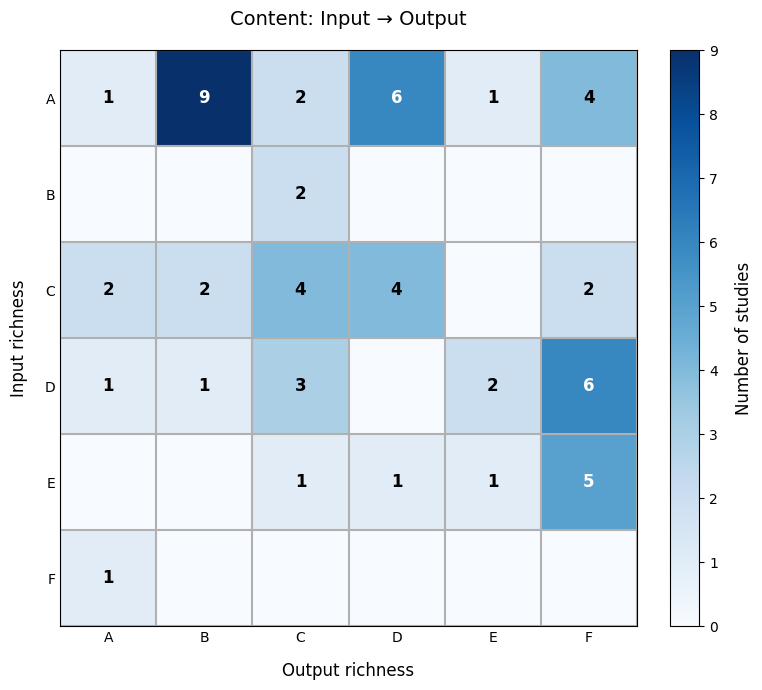

In [63]:
coocurence_heatmap(cooc)

In [62]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def coocurence_heatmap(cooc):

    title_fontsize = 14
    fontsize = 12

    # ------------------------------------------------------------
    # 1. Load the co-occurrence data
    # ------------------------------------------------------------
    # file_path = "input_output_content_groups_cooc.csv"
    # df = pd.read_csv(file_path)
    df = cooc

    required_columns = {
        "input_content_grouped",
        "output_content_grouped",
        "Count",
    }

    missing_columns = required_columns - set(df.columns)
    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")


    # ------------------------------------------------------------
    # 2. Define the intended category order
    # ------------------------------------------------------------
    input_order = [
        "A: non-geometric",
        "B: building elements (+ non-geometric)",
        "C: floorplan contour (+ non-geometric)",
        "D: floorplan contour + building elements (+ non-geometric)",
        "E: floorplan/space geometry (+ any other)",
        "F: empty condition",
    ]

    output_order = [
        "A: walls/columns (+ other building elements)",
        "B: space geometry",
        "C: space geometry + building elements x1",
        "D: space geometry + building elements x2",
        "E: space geometry + building elements x3",
        "F: space geometry + building elements x4+",
    ]

    # ------------------------------------------------------------
    # 3. Convert the long-form table into a matrix
    # ------------------------------------------------------------
    heatmap_data = (
        df.pivot_table(
            index="input_content_grouped",
            columns="output_content_grouped",
            values="Count",
            aggfunc="sum",
            fill_value=0,
        )
        .reindex(index=input_order, columns=output_order, fill_value=0)
    )


    # ------------------------------------------------------------
    # 4. Create shorter labels for the figure
    # ------------------------------------------------------------
    ### v1
    # input_labels = [
    #     "Non-geometric",
    #     "Building elements\n(+ non-geometric)",
    #     "Floor plan contour\n(+ non-geometric)",
    #     "Contour + building elements\n(+ non-geometric)",
    #     "Floor plan/space geometry\n(+ any other)",
    #     "Empty condition",
    # ]

    # output_labels = [
    #     "Walls/columns\n(+ other elements)",
    #     "Space geometry",
    #     "Geometry +\n1 element type",
    #     "Geometry +\n2 element types",
    #     "Geometry +\n3 element types",
    #     "Geometry +\n4+ element types",
    # ]

    ### v2
    # input_labels = [
    #     "A: non-geometric",
    #     "B: building elements\n(+ non-geometric)",
    #     "C: contour\n(+ non-geometric)",
    #     "D: contour + building elements\n(+ non-geometric)",
    #     "E: floorplan/space geometry\n(+ any other)",
    #     "F: empty condition",
    # ]

    # output_labels = [
    #     "A: walls/columns\n(+ other building elements)",
    #     "B: space geometry",
    #     "C: space geometry +\nbuilding elements x1",
    #     "D: space geometry +\nbuilding elements x2",
    #     "E: space geometry +\nbuilding elements x3",
    #     "F: space geometry +\nbuilding elements x4+",
    # ]

    ### v3
    input_labels = [
        "A",
        "B",
        "C",
        "D",
        "E",
        "F",
    ]

    output_labels = [
        "A",
        "B",
        "C",
        "D",
        "E",
        "F",
    ]

    # ------------------------------------------------------------
    # 5. Plot the heatmap
    # ------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 7))

    image = ax.imshow(
        heatmap_data.to_numpy(),
        # aspect="auto",
        aspect=1,
        interpolation="none",
        cmap="Blues",
        # cmap="Greens",
        # cmap="Oranges",
        # cmap="Purples",
        # cmap="YlGnBu",
        # cmap="viridis",
        # cmap="cividis",
    )

    # Axis labels
    ax.set_xticks(np.arange(len(output_labels)))
    ax.set_yticks(np.arange(len(input_labels)))

    ax.set_xticklabels(output_labels, fontsize=10)
    ax.set_yticklabels(input_labels, fontsize=10)

    # plt.setp(
    #     ax.get_xticklabels(),
    #     rotation=35,
    #     ha="right",
    #     rotation_mode="anchor",
    # )

    ax.set_xlabel(
        # "Generated output", 
        "Output richness",
        fontsize=fontsize, 
        labelpad=12
    )
    ax.set_ylabel(
        # "Conditioning input", 
        "Input richness",
        fontsize=fontsize, 
        labelpad=12
    )
    ax.set_title(
        "Content: Input → Output",
        fontsize=title_fontsize,
        pad=18,
    )


    # ------------------------------------------------------------
    # 6. Annotate cells
    # ------------------------------------------------------------
    values = heatmap_data.to_numpy()
    threshold = values.max() / 2

    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values[row, col]

            # Hide zero values to reduce visual clutter
            if value == 0:
                continue

            text_color = "white" if value > threshold else "black"

            ax.text(
                col,
                row,
                f"{value:g}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=fontsize,
                fontweight="bold",
            )


    # ------------------------------------------------------------
    # 7. Add cell boundaries
    # ------------------------------------------------------------
    ax.set_xticks(
        np.arange(-0.5, len(output_labels), 1),
        minor=True,
    )
    ax.set_yticks(
        np.arange(-0.5, len(input_labels), 1),
        minor=True,
    )

    ax.grid(
        which="minor",
        linewidth=1.5,
    )

    ax.tick_params(which="minor", bottom=False, left=False)
    ax.tick_params(axis="both", which="major", length=0)


    # ------------------------------------------------------------
    # 8. Add color bar
    # ------------------------------------------------------------
    colorbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.035,
        pad=0.03,
    )

    colorbar.set_label(
        "Number of studies", 
        rotation=90, 
        labelpad=12,
        fontsize=fontsize,
    )


    # ------------------------------------------------------------
    # 9. Final formatting and export
    # ------------------------------------------------------------
    fig.tight_layout()

    # plt.savefig(
    #     "input_output_heatmap.png",
    #     dpi=300,
    #     bbox_inches="tight",
    # )

    # plt.savefig(
    #     "input_output_heatmap.pdf",
    #     bbox_inches="tight",
    # )

    plt.show()


# DATASET

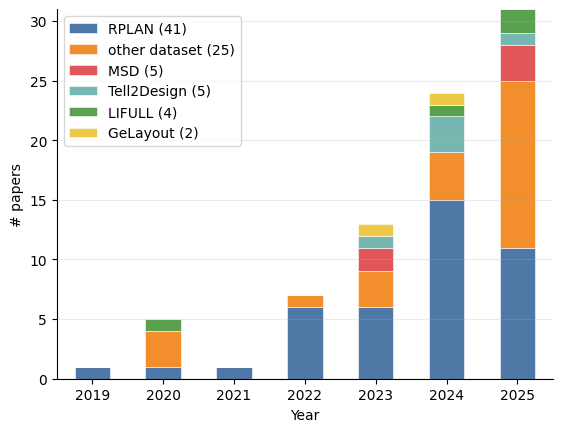

In [9]:
plot_dataset_per_year(df)

# GENERALIZABILITY

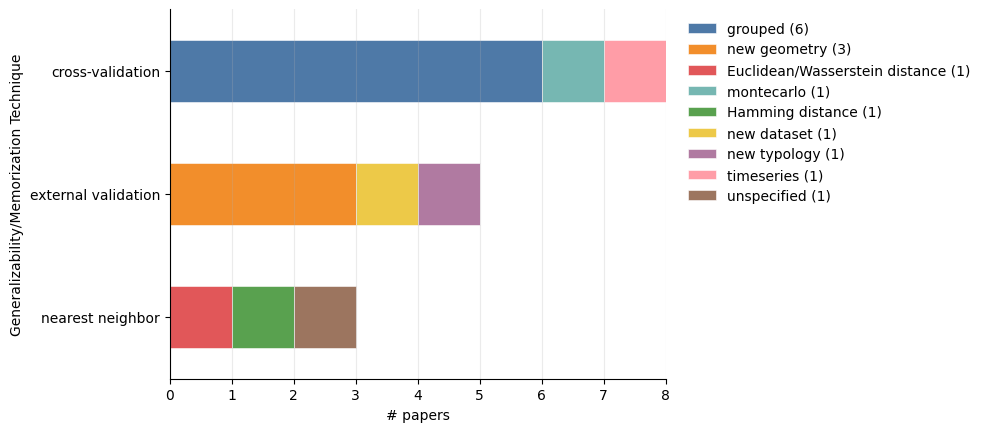

In [10]:
plot_generalizability(df)

# USER STUDIES

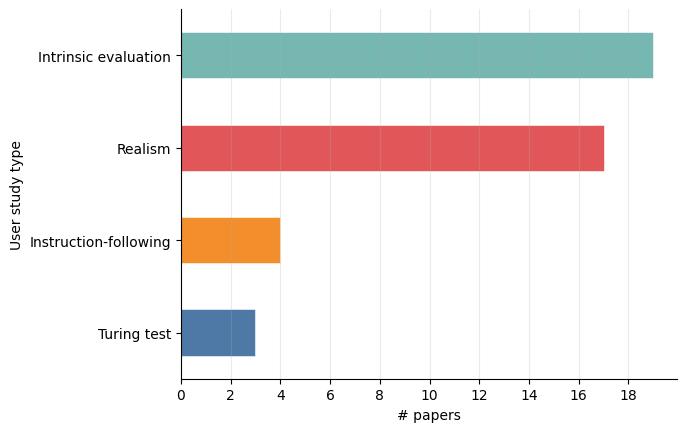

In [8]:
plot_user_studies(df)

# METRICS: INDIVIDUAL

In [4]:
df_metrics

,Similarity,Instruction-Following,Normative Compliance,Intrinsic
0,[Absent],[Absent],[Absent],"[Attributes: RAI, Attributes: Space Property P..."
1,"[Pixels: classification performance, Regions: ...",[Absent],[Absent],[Absent]
2,"[Embeddings: FID, Regions: IoU-based]",[Absent],[Absent],[Absent]
3,[Regions: IoU-based],[Absent],[Absent],[Absent]
4,[Embeddings: FID],[Absent],[Absent],[Absent]
...,...,...,...,...
67,"[Graphs: Graph Compatibility, Regions: IoU-based]",[Absent],[Absent],[Absent]
68,[Absent],[Absent],[Absent],[Absent]
69,[Absent],[Absent],[Absent],[Absent]
70,"[Attributes: VGA, Attributes: room statistics]",[Absent],[Absent],[Regions: Percent of isolated rooms]


In [ ]:
df_metrics["Normative Compliance"].to_list()

0     [Absent]
1     [Absent]
2     [Absent]
3     [Absent]
4     [Absent]
        ...   
67    [Absent]
68    [Absent]
69    [Absent]
70    [Absent]
71    [Absent]
Name: Normative Compliance, Length: 72, dtype: object

In [26]:
s1 = set.union(*[set(x) for x in df_metrics["Similarity"].to_list()]) - {"Absent"}
s1

{'Attributes: VGA',
 'Attributes: room class prediction',
 'Attributes: room statistics',
 'Embeddings: Coverage',
 'Embeddings: Density',
 'Embeddings: FID',
 'Embeddings: KID',
 'Embeddings: LPIPS',
 'Embeddings: real/fake',
 'Graphs: GED',
 'Graphs: Graph Compatibility',
 'Pixels: MAE',
 'Pixels: MAPE',
 'Pixels: MSE',
 'Pixels: PSNR',
 'Pixels: R2',
 'Pixels: RMSE',
 'Pixels: SSIM',
 'Pixels: classification performance',
 'Pixels: sMAPE',
 'Regions: Boundary Chamfer Distance',
 'Regions: Boundary IoU-based',
 'Regions: IoU-based'}

In [38]:
s2 = set.union(*[set(x) for x in df_metrics["Normative Compliance"].to_list()]) - {"Absent"}
s2 

{'Attributes: AEC',
 'Attributes: EUI',
 'Attributes: accessibility check',
 'Attributes: functional rationality',
 'Graphs: adjacency violations'}

In [ ]:

for metric in s1:


### Table with all quantitative metrics

In [44]:
app_table = metrics_by_representation(df_metrics)
app_table

,Representations,Similarity,Instruction-Following,Normative Compliance,Intrinsic
0,Pixels,"[classification performance, SSIM, PSNR, MAE, ...",[],[],[]
1,Regions,"[IoU-based, Boundary Chamfer Distance, Boundar...","[Boundary IoU, Boundary Compatibility]",[],"[Vectorization Success Rate, Geometric validit..."
2,Graphs,"[GED, Graph Compatibility]",[GED],[adjacency violations],[]
3,Embeddings,"[FID, LPIPS, real/fake, Coverage, Density, KID]",[CLIP Score],[],[IS]
4,Attributes,"[room statistics, room class prediction, VGA]",[Prompt Consistency],"[AEC, accessibility check, EUI, functional rat...","[RAI, Space Property Proportion, Shortest-path..."


In [43]:
import ast
import pandas as pd


def _parse_cell(cell):
    """
    Convert a cell into a list of strings.

    Supports:
    - Python lists;
    - string representations of lists;
    - individual strings;
    - missing values.
    """
    if cell is None or (
        not isinstance(cell, (list, tuple, set))
        and pd.isna(cell)
    ):
        return []

    if isinstance(cell, (list, tuple, set)):
        return list(cell)

    if isinstance(cell, str):
        cell = cell.strip()

        if not cell or cell.lower() in {
            "[absent]",
            "absent",
            "nan",
            "none",
        }:
            return []

        # Handle strings such as:
        # "['Embeddings: FID', 'Regions: IoU-based']"
        try:
            parsed = ast.literal_eval(cell)

            if isinstance(parsed, (list, tuple, set)):
                return list(parsed)

            if isinstance(parsed, str):
                return [parsed]

        except (ValueError, SyntaxError):
            pass

        # Fallback for strings such as:
        # "[Embeddings: FID, Regions: IoU-based]"
        return [
            item.strip()
            for item in cell.strip("[]").split(",")
            if item.strip()
        ]

    return [str(cell)]


def metrics_by_representation(df):
    """
    Transform a dataframe whose cells contain entries such as:

        ["Pixels: classification performance",
         "Regions: IoU-based"]

    into a dataframe where:

    - columns remain unchanged;
    - rows are representation types;
    - each cell contains the unique metric names associated with that
      representation and evaluation category.
    """

    representation_order = [
        "Pixels",
        "Regions",
        "Graphs",
        "Embeddings",
        "Attributes",
    ]

    result = pd.DataFrame(
        index=representation_order,
        columns=df.columns,
        dtype=object,
    )

    for column in df.columns:
        collected = {
            representation: []
            for representation in representation_order
        }

        for cell in df[column]:
            for item in _parse_cell(cell):
                item = str(item).strip()

                if item.lower() in {
                    "[absent]",
                    "absent",
                    "",
                }:
                    continue

                if ":" not in item:
                    continue

                representation, metric = item.split(":", 1)

                representation = representation.strip()
                metric = metric.strip()

                if (
                    representation in collected
                    and metric
                    and metric not in collected[representation]
                ):
                    collected[representation].append(metric)

        for representation in representation_order:
            result.loc[representation, column] = collected[representation]


    result.index.name = "Representations"
    result = result.reset_index()
    result.to_csv("data/results/metrics_by_repr.csv")

    return result

In [5]:
from utils_synthesis import _get_unique_metrics, _get_s_full

In [6]:
s_full = _get_s_full(df_metrics)
s_full 

0     {Attributes: RAI, Attributes: Space Property P...
1     {Pixels: classification performance, Regions: ...
2                 {Regions: IoU-based, Embeddings: FID}
3                                  {Regions: IoU-based}
4                                     {Embeddings: FID}
                            ...                        
67    {Graphs: Graph Compatibility, Regions: IoU-based}
68                                             {Absent}
69                                             {Absent}
70    {Attributes: room statistics, Regions: Percent...
71    {Embeddings: KID, Embeddings: IS, Embeddings: ...
Length: 72, dtype: object

In [63]:
s_full.loc[14]

{'Pixels: MAE',
 'Pixels: MAPE',
 'Pixels: MSE',
 'Pixels: PSNR',
 'Pixels: R2',
 'Pixels: RMSE',
 'Pixels: sMAPE'}

In [54]:
df_unique

,counts
metric,
Attributes: RAI,1
Regions: Vectorization Success Rate,1
Pixels: R2,1
Attributes: functional rationality,1
Attributes: room class prediction,1
Embeddings: Coverage,1
Pixels: classification performance,1
Pixels: PSNR,11
Regions: Boundary IoU,3


In [48]:
df_single = df_unique[df_unique.counts == 1]
df_multiple = df_unique[df_unique.counts > 1]

In [52]:
num_singles = s_full.apply(lambda x: 1 if len(x.intersection(s_single)) > 0 else 0).sum()
num_singles

np.int64(17)

In [49]:
df_single

,counts
metric,
Attributes: RAI,1
Regions: Vectorization Success Rate,1
Pixels: R2,1
Attributes: functional rationality,1
Attributes: room class prediction,1
Embeddings: Coverage,1
Pixels: classification performance,1
Regions: Boundary Compatibility,1
Regions: Boundary IoU-based,1


In [50]:
df_multiple

,counts
metric,
Pixels: PSNR,11
Regions: Boundary IoU,3
Pixels: MAE,3
Attributes: accessibility check,2
Attributes: room statistics,4
Embeddings: FID,39
Regions: IoU-based,22
Attributes: Prompt Consistency,5
Embeddings: KID,3


In [53]:
df_single

,counts
metric,
Attributes: RAI,1
Regions: Vectorization Success Rate,1
Pixels: R2,1
Attributes: functional rationality,1
Attributes: room class prediction,1
Embeddings: Coverage,1
Pixels: classification performance,1
Regions: Boundary Compatibility,1
Regions: Boundary IoU-based,1


In [51]:
s_single = set(df_single.index)
s_single

{'Attributes: AEC',
 'Attributes: ARS',
 'Attributes: Connectivity Ratio',
 'Attributes: Min/Max Area ratio',
 'Attributes: RAI',
 'Attributes: Room count distribution',
 'Attributes: Self-Consistency',
 'Attributes: Shortest-path sanity',
 'Attributes: Space Property Proportion',
 'Attributes: VGA',
 'Attributes: functional rationality',
 'Attributes: room class prediction',
 'Embeddings: CLIP Score',
 'Embeddings: Coverage',
 'Embeddings: Density',
 'Graphs: adjacency violations',
 'Pixels: MAPE',
 'Pixels: R2',
 'Pixels: RMSE',
 'Pixels: classification performance',
 'Pixels: sMAPE',
 'Regions: Boundary Chamfer Distance',
 'Regions: Boundary Compatibility',
 'Regions: Boundary IoU-based',
 'Regions: Geometric validity',
 'Regions: Percent of isolated rooms',
 'Regions: Vectorization Success Rate'}

In [7]:
df_unique = _get_unique_metrics(s_full).set_index("metric")
df_unique 

,counts
metric,
Attributes: RAI,1
Regions: Vectorization Success Rate,1
Pixels: R2,1
Attributes: functional rationality,1
Attributes: room class prediction,1
Embeddings: Coverage,1
Pixels: classification performance,1
Pixels: PSNR,11
Regions: Boundary IoU,3


In [47]:
df_unique.sort_values("counts", ascending=False)

,counts
metric,
Embeddings: FID,39
Regions: IoU-based,22
Graphs: GED,22
Pixels: PSNR,11
Pixels: SSIM,11
Attributes: Prompt Consistency,5
Attributes: room statistics,4
Embeddings: KID,3
Attributes: EUI,3


num of unique metrics: 44
num of one-time-use metrics: 27
num of reusable metrics: 17


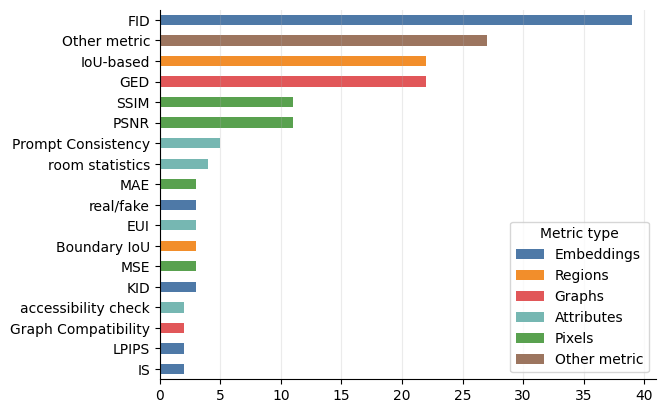

In [4]:
plot_num_papers_per_metric(df_metrics)

# METRICS: GROUPED

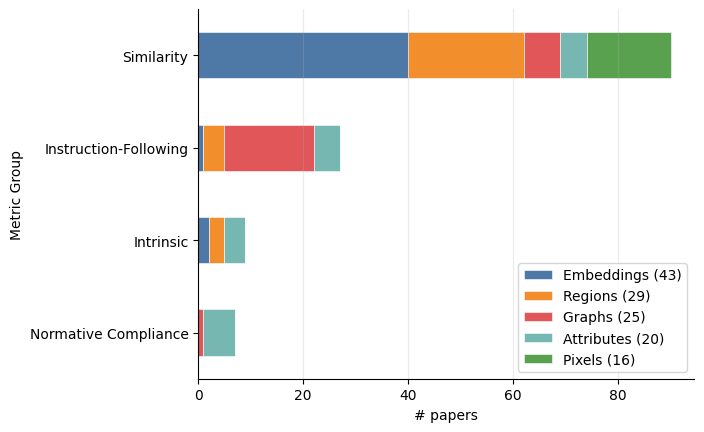

In [12]:
plot_stacked_bars(df_metrics)